# Performance profiling

Show simulation times for advection, diffusion and BGC operators for NPZD and ECOSMO simulations.

Since the computations for profiling can be extensive, this notebook plots pre-computed results. Therefore, <mark>generate the profiling results beforehand</mark> using the script $\verb|performance_profiling.py|$ or <mark>download pre-computed results from Zenodo</mark>.

### Download files from Zenodo

Whether you generate profiling results with $\verb|performance_profiling.py|$ or use pre-computed results, you need to download additional files from Zenodo: <https://zenodo.org/uploads/23670437>

Please store them in the following directory:

In [ ]:
base_folder = '/gpfs/work/nimtz/zenodo/'  # the directory of your Zenodo download

### Compute profiling results (optional)

For computing profiling results yourself, execute the script $\verb|performance_profiling.py|$. You need to run it multiple times with different settings (e.g., tridiagonal solvers, devices, ...) that are specified in the script. Modify the script to vary settings. By default, the script will save the profiling results to the location of the pre-computed results. If you change it, please modify the following path accordingly:

In [ ]:
load_path = base_folder + 'marinade_github_forcing_data/nns_npzd/base_simulation_5y/performance_profiling/'  # the directory of profiling results
load_path_ecosmo = base_folder + 'marinade_github_forcing_data/nns_ecosmo/base_simulation_5y/performance_profiling/'

Next, we import required libraries, load the profiling results and plot them.

In [ ]:
import torch
import pickle
import matplotlib.pyplot as plt

In [ ]:
devices = ('cpu', 'cuda', 'cpu', 'cuda', 'cpu', 'cuda', 'cpu', 'cpu', 'cpu')#, 'cuda')
modes_rollout = (False, False, False, False, False, False, True, True, True)#, True)
dif_methods = (None, None, 'paracr', 'paracr', 'linalg', 'linalg', None, 'paracr', 'linalg')
labels = [f'{"rollout" if r else "parallel"}\n{d}\n{"Thomas" if m is None else m}' for d, r, m in zip(devices, modes_rollout, dif_methods)]

devices_ecosmo = ('cpu', 'cuda', 'cpu', 'cuda', 'cpu', 'cpu', 'cpu', 'cpu')#, 'cuda')
modes_rollout_ecosmo = (False, False, False, False, False, True, True, True)#, True)
dif_methods_ecosmo = (None, None, 'paracr', 'paracr', 'linalg', None, 'paracr', 'linalg')
labels_ecosmo = [f'{"rollout" if r else "parallel"}\n{d}\n{"Thomas" if m is None else m}' for d, r, m in zip(devices_ecosmo, modes_rollout_ecosmo, dif_methods_ecosmo)]

In [ ]:
times = []
for d, r, m in zip(devices, modes_rollout, dif_methods):
    try:
        with open(load_path+f'_{d}_{"rollout" if r else "parallel"}_nograd{"_thomas" if m is None else "_"+m}.pkl', 'rb') as file:
            times.append(pickle.load(file)[:3])
    except FileNotFoundError:
        times.append(torch.full_like(times[-1], torch.nan))
times_mean = torch.stack([t.mean(dim=-1) for t in times], dim=-1)
times_mean_cumsum = torch.cumsum(times_mean, dim=0)

In [ ]:
times_ecosmo = []
for d, r, m in zip(devices_ecosmo, modes_rollout_ecosmo, dif_methods_ecosmo):
    try:
        with open(load_path_ecosmo+f'_{d}_{"rollout" if r else "parallel"}_nograd{"_thomas" if m is None else "_"+m}.pkl', 'rb') as file:
            times_ecosmo.append(pickle.load(file)[:3])
    except FileNotFoundError:
        print(f'file _{d}_{"rollout" if r else "parallel"}_nograd{"_thomas" if m is None else "_"+m}.pkl not found')
        times_ecosmo.append(torch.full((3, 43824 if r else 100), torch.nan))
times_ecosmo_mean = torch.stack([t.mean(dim=-1) for t in times_ecosmo], dim=-1)
times_ecosmo_mean_cumsum = torch.cumsum(times_ecosmo_mean, dim=0)

In [ ]:
steps_rollout = 43824  # five years with an hourly time step = (5 * 365 + 1) * 24
assert steps_rollout == (5*365+1)*24

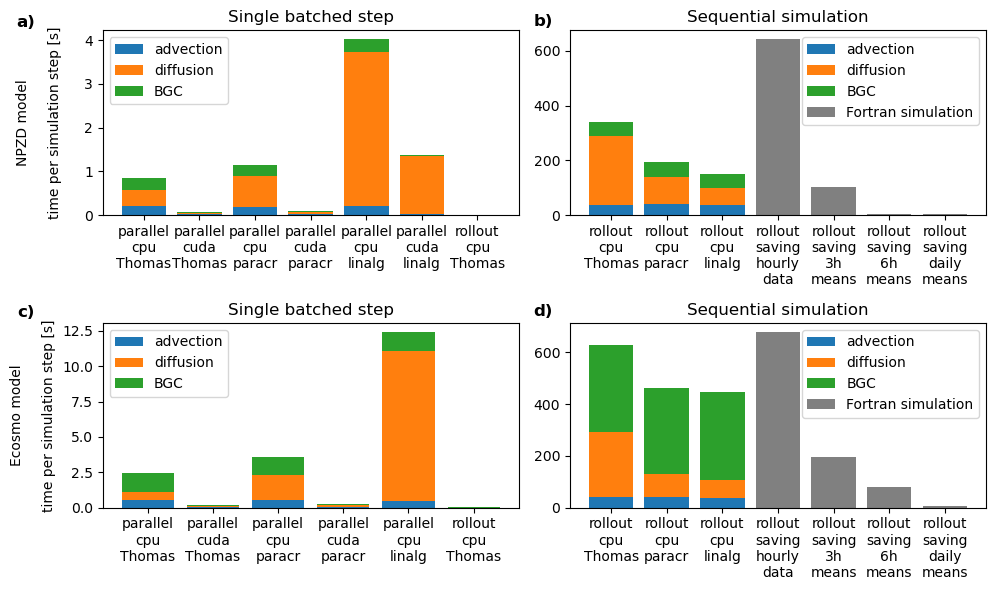

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(10, 6))

title_left = 'Single batched step'
title_right = 'Sequential simulation'

n_left = 7
for i, l in zip(range(3), ('advection', 'diffusion', 'BGC')):
    ax[0,0].bar(labels[:n_left], times_mean[i,:n_left], bottom=times_mean_cumsum[i-1,:n_left] if i > 0 else None, label=l)
for i, l in zip(range(3), ('advection', 'diffusion', 'BGC')):
    ax[0,1].bar(labels[n_left-1:], times_mean[i,n_left-1:]*steps_rollout, bottom=times_mean_cumsum[i-1,n_left-1:]*steps_rollout if i > 0 else None, label=l)
ax[0,1].bar('rollout\nsaving\nhourly\ndata', 643.0, color='grey', label='Fortran simulation')  # performed with sync to disk on close only
ax[0,1].bar('rollout\nsaving\n3h\nmeans', 102.0, color='grey')
ax[0,1].bar('rollout\nsaving\n6h\nmeans', 3.0, color='grey')
ax[0,1].bar('rollout\nsaving\ndaily\nmeans', 3.0, color='grey')
ax[0,0].set_ylabel('NPZD model\n\ntime per simulation step [s]\n')
ax[0,0].set_title(title_left); ax[0,1].set_title(title_right)
ax[0,0].legend(loc='upper left'); ax[0,1].legend()

n_left = 6
for i, l in zip(range(3), ('advection', 'diffusion', 'BGC')):
    ax[1,0].bar(labels_ecosmo[:n_left], times_ecosmo_mean[i,:n_left], bottom=times_ecosmo_mean_cumsum[i-1,:n_left] if i > 0 else None, label=l)
for i, l in zip(range(3), ('advection', 'diffusion', 'BGC')):
    ax[1,1].bar(labels_ecosmo[n_left-1:], times_ecosmo_mean[i,n_left-1:]*steps_rollout, bottom=times_ecosmo_mean_cumsum[i-1,n_left-1:]*steps_rollout if i > 0 else None, label=l)
ax[1,1].bar('rollout\nsaving\nhourly\ndata', 680.0, color='grey', label='Fortran simulation')  # performed with sync to disk on close only
ax[1,1].bar('rollout\nsaving\n3h\nmeans', 197.0, color='grey')
ax[1,1].bar('rollout\nsaving\n6h\nmeans', 80.0, color='grey')
ax[1,1].bar('rollout\nsaving\ndaily\nmeans', 5.0, color='grey')
ax[1,0].set_ylabel('Ecosmo model\n\ntime per simulation step [s]')
ax[1,0].set_title(title_left); ax[1,1].set_title(title_right)
for i, a, y in zip(range(100), ('a', 'b', 'c', 'd'), (4.3, 690, 13.5, 740)):
    ax.flat[i].text(-1.4 - 0.9*(i==0) - 0.6*(i==2), y, f'{a})', size="large", fontweight="bold")
ax[1,0].legend(); ax[1,1].legend(); plt.tight_layout(); plt.show()

Note that the Fortran simulation results in the figure are not computed with MARINADE and are hard-coded in the plotting code above. To compute them yourself, you would need to download the GOTM Fortran code, compile it on your device and run the executable. The total runtime will be documented in the GOTM output file. Our GOTM output files along with the corresponding slurm script are included in the Zenodo dataset.